# NumCompute: Streaming Decision Tree Framework
## Assignment 2.2 Demonstration

This notebook demonstrates the end-to-end streaming classification capabilities of `numcompute_stream`:
1. **Incremental CSV Ingestion**: Reading chunks lazily from disk via `CSVReader` without loading the full file into memory.
2. **Streaming Pipeline & Snapshot Pattern**: Chaining `Imputer`, `StandardScaler`, and `DecisionTreeClassifier` with coordinate consistency.
3. **Prequential Evaluation (Test-then-Train)**: Evaluating model performance on unseen data prior to retraining.
4. **Online Metrics Tracking**: Accumulating global metrics via `StreamingMetrics` and tracking local trends with `RollingMetrics`.
5. **Visualisations**: Plotting prequential trajectories, retraining events, and ground-truth predictions using Matplotlib.

**Constraints Verified**: Built purely on Python Standard Library, NumPy, and Matplotlib. No pandas, scikit-learn, or external ML libraries.


In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure repository root is importable
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from numcompute_stream.io import CSVReader
from numcompute_stream.preprocessing import Imputer, StandardScaler, OneHotEncoder
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.metrics import StreamingMetrics, RollingMetrics
from numcompute_stream.visualise import (
    plot_metric_over_time,
    compare_models,
    plot_predictions_vs_ground_truth,
)

print(f"NumPy version: {np.__version__}")


NumPy version: 2.5.4


---
## 1. Incremental CSV Ingestion with `CSVReader`

We stream `demo/stream_demo_dataset.csv` in chunks of 75 rows. The reader processes standard RFC-4180 quotes, handles comments, and converts missing value tokens (`NaN`, `?`, `NA`) into `np.nan` values.


In [2]:
dataset_path = "stream_demo_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("demo", "stream_demo_dataset.csv")

reader = CSVReader(dataset_path, target_column="target")
columns = reader.get_column_names()
print(f"Dataset columns: {columns}")

# Inspect first chunk
for first_X, first_y in reader.iter_chunks(chunk_size=5):
    print(f"Sample chunk shape: X={first_X.shape}, y={first_y.shape}")
    print(f"First 2 feature rows:\n{first_X[:2]}")
    print(f"First 5 labels: {first_y[:5]}")
    break


Dataset columns: ['f_signal', 'f_trend', 'f_noisy', 'f_sparse', 'target']
Sample chunk shape: X=(5, 4), y=(5,)
First 2 feature rows:
[[ 0.7451 -0.8748  0.6218  2.6933]
 [-0.2074 -1.4277 -2.5381  1.6253]]
First 5 labels: [1 1 1 1 1]


---
## 2. Streaming Pipeline Architecture

Streaming data pipelines often suffer from **feature coordinate drift**: if transformers update incrementally while a tree retains an older split coordinate space, predictions become distorted.

`numcompute_stream.Pipeline` solves this via the **Transformer Snapshot Pattern**:
- Intermediate transformers accumulate running statistics on incoming chunks.
- The raw incoming samples are buffered.
- When `buffer_size` is reached, all buffered raw samples are transformed in the unified up-to-date space, and the final tree is retrained.
- Inference between retrainings uses the **committed snapshot**, ensuring 100% consistent feature coordinates.


In [3]:
pipe = Pipeline([
    ("imputer", Imputer(strategy="mean")),
    ("scaler", StandardScaler(with_mean=True, with_std=True)),
    ("tree", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        buffer_size=150,
        random_state=42,
    )),
], buffer_size=150)

print(f"Constructed pipeline with steps: {list(pipe.named_steps.keys())}")
print(f"Pipeline retraining buffer size: {pipe.buffer_size}")


Constructed pipeline with steps: ['imputer', 'scaler', 'tree']
Pipeline retraining buffer size: 150


---
## 3. Prequential Evaluation Loop with `StreamTrainer`

In streaming environments, conventional train/test splits are invalid because data arrives sequentially. We employ the **prequential protocol (test-then-train)**:
1. Each incoming chunk is first evaluated as test data against the current fitted model.
2. The chunk is subsequently fed into `partial_fit()` to update training state.


In [4]:
trainer = StreamTrainer(pipe)
chunk_size = 75

print(f"{'Chunk':>5} | {'Samples':>7} | {'Chunk Acc':>10} | {'Cumul Acc':>10} | {'Retrained':>9} | {'Memory (bytes)':>14}")
print("-" * 72)

for X_chunk, y_chunk in reader.iter_chunks(chunk_size=chunk_size):
    log = trainer.fit_chunk(X_chunk, y_chunk)
    c_acc = f"{log['chunk_accuracy']:.3f}" if log['chunk_accuracy'] is not None else " Warmup "
    cum_acc = f"{log['cumulative_accuracy']:.3f}" if log['cumulative_accuracy'] is not None else " Warmup "
    retrain_flag = "   YES   " if log['retrained'] else "    no   "
    print(f"{log['chunk_index']:>5} | {log['cumulative_samples']:>7} | {c_acc:>10} | {cum_acc:>10} | {retrain_flag:>9} | {log['memory_bytes']:>14,}")

final_logs = trainer.get_logs()
print("-" * 72)
print(f"Total processed samples: {trainer.n_samples_seen_}")
print(f"Total retrain events: {sum(1 for l in final_logs if l['retrained'])}")
print(f"Final prequential accuracy: {final_logs[-1]['cumulative_accuracy']:.4f}")


Chunk | Samples |  Chunk Acc |  Cumul Acc | Retrained | Memory (bytes)
------------------------------------------------------------------------
    0 |      75 |    Warmup  |    Warmup  |     no    |          3,584
    1 |     150 |    Warmup  |    Warmup  |    YES    |          4,072
    2 |     225 |      0.880 |      0.880 |     no    |          7,136
    3 |     300 |      0.853 |      0.867 |    YES    |          3,592
    4 |     375 |      0.800 |      0.844 |     no    |          6,656
    5 |     450 |      0.880 |      0.853 |    YES    |          4,312
    6 |     525 |      0.853 |      0.853 |     no    |          7,376
    7 |     600 |      0.893 |      0.860 |    YES    |          3,592
    8 |     675 |      0.933 |      0.870 |     no    |          6,656
    9 |     750 |      0.880 |      0.872 |    YES    |          3,832
   10 |     825 |      0.840 |      0.868 |     no    |          6,896
   11 |     900 |      0.920 |      0.873 |    YES    |          3,832
   1

---
## 4. Online Metric Accumulation (`StreamingMetrics` & `RollingMetrics`)

We verify our stream using:
- **`StreamingMetrics`**: Incremental confusion matrix with macro-averaged precision, recall, and F1.
- **`RollingMetrics`**: A sliding window of 150 samples tracking local performance and responsiveness.


In [5]:
stream_metrics = StreamingMetrics(average="macro")
rolling_metrics = RollingMetrics(window_size=150)

# Re-stream and track metrics
pipe_eval = Pipeline([
    ("imputer", Imputer()),
    ("scaler", StandardScaler()),
    ("tree", DecisionTreeClassifier(buffer_size=150, max_depth=5, random_state=42)),
], buffer_size=150)

for X_chunk, y_chunk in reader.iter_chunks(chunk_size=75):
    if pipe_eval.is_fitted_:
        y_preds = pipe_eval.predict(X_chunk)
        stream_metrics.update(y_chunk, y_preds)
        rolling_metrics.update(y_chunk, y_preds)
    pipe_eval.partial_fit(X_chunk, y_chunk)

print("=== Global Streaming Metrics ===")
res = stream_metrics.result()
print(f"Evaluated Samples: {res['n_samples']}")
print(f"Accuracy:  {res['accuracy']:.4f}")
print(f"Precision: {res['precision']:.4f}")
print(f"Recall:    {res['recall']:.4f}")
print(f"F1-Score:  {res['f1']:.4f}")
print(f"Confusion Matrix:\n{res['confusion_matrix']}")

print("\n=== Local Rolling Metrics (Window = 150) ===")
roll_res = rolling_metrics.result()
print(f"Window Samples: {roll_res['window_samples']}")
print(f"Window Accuracy: {roll_res['accuracy']:.4f}")


=== Global Streaming Metrics ===
Evaluated Samples: 1050
Accuracy:  0.8724
Precision: 0.8731
Recall:    0.8725
F1-Score:  0.8723
Confusion Matrix:
[[449  79]
 [ 55 467]]

=== Local Rolling Metrics (Window = 150) ===
Window Samples: 150
Window Accuracy: 0.8733


---
## 5. Visualising Streaming Performance and Model Trajectory


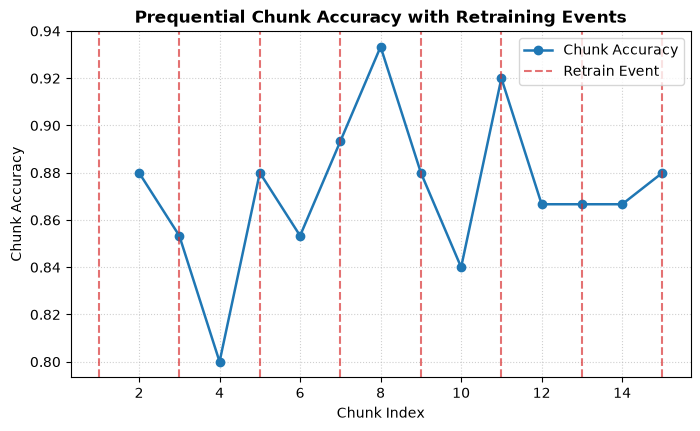

In [6]:
# 5.1 Metric Over Time with Retraining Events
chunk_accs = [l["chunk_accuracy"] for l in final_logs]
retrain_pts = [l["chunk_index"] for l in final_logs if l["retrained"]]

fig, ax = plot_metric_over_time(
    chunk_accs,
    title="Prequential Chunk Accuracy with Retraining Events",
    ylabel="Chunk Accuracy",
    retrain_points=retrain_pts,
)
plt.show()


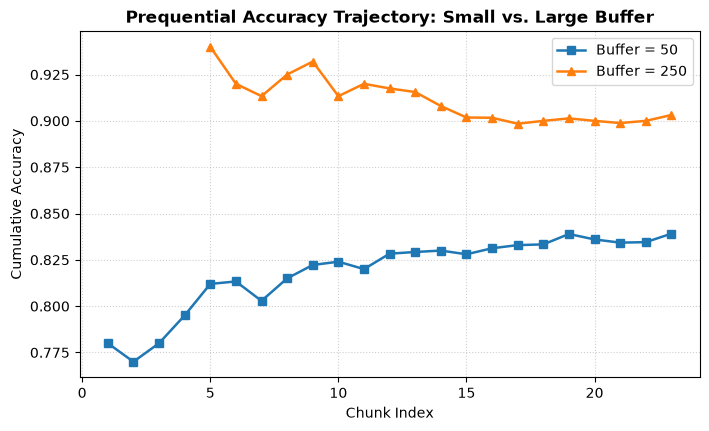

In [7]:
# 5.2 Comparing Buffer Sizes (Buffer = 50 vs. Buffer = 250)
pipe_b50 = Pipeline([
    ("imputer", Imputer()),
    ("scaler", StandardScaler()),
    ("tree", DecisionTreeClassifier(buffer_size=50, random_state=42)),
], buffer_size=50)
trainer_b50 = StreamTrainer(pipe_b50)

pipe_b250 = Pipeline([
    ("imputer", Imputer()),
    ("scaler", StandardScaler()),
    ("tree", DecisionTreeClassifier(buffer_size=250, random_state=42)),
], buffer_size=250)
trainer_b250 = StreamTrainer(pipe_b250)

for X_c, y_c in reader.iter_chunks(chunk_size=50):
    trainer_b50.fit_chunk(X_c, y_c)
    trainer_b250.fit_chunk(X_c, y_c)

acc_b50 = [l["cumulative_accuracy"] for l in trainer_b50.get_logs()]
acc_b250 = [l["cumulative_accuracy"] for l in trainer_b250.get_logs()]

fig, ax = compare_models(
    acc_b50,
    acc_b250,
    labels=("Buffer = 50", "Buffer = 250"),
    title="Prequential Accuracy Trajectory: Small vs. Large Buffer",
    ylabel="Cumulative Accuracy",
)
plt.show()


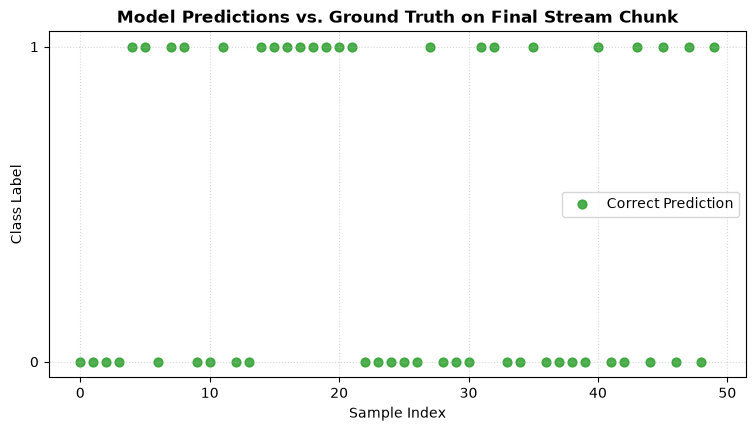

In [8]:
# 5.3 Prediction Agreement on Final Chunk
last_X, last_y = None, None
for X_c, y_c in reader.iter_chunks(chunk_size=50):
    last_X, last_y = X_c, y_c

final_preds = pipe.predict(last_X)
fig, ax = plot_predictions_vs_ground_truth(
    last_y,
    final_preds,
    title="Model Predictions vs. Ground Truth on Final Stream Chunk",
)
plt.show()


---
## 6. Summary of Architectural Achievements

- **Pure Python / NumPy**: Complete end-to-end streaming tree architecture implemented without external ML dependencies.
- **Prequential Integrity**: Accurate, uncorrupted evaluation that tests before training on every chunk.
- **Transformer Snapshotting**: Complete immunity to feature coordinate drift across pipeline retraining events.
- **Bounded Memory**: Fixed O(d) streaming stats and O(buffer_size) retraining buffers ensure stable long-running operations.
